In [15]:
import numpy as np
import matplotlib.pyplot as plt

def W_kn_N (k,n,N):
    return np.exp(-2j * np.pi * k * n / N)

def DFT(x_n, N):

    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da DFT
    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        X_k[k] = np.sum(W_n[k] * x_n )

    return X_k

def IDFT(X_k, N):
    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da IDFT
    x_n = np.zeros(N, dtype=complex)
    for n in range(N):
        x_n[n] = np.sum( np.conj(W_n[:,n]) * X_k ) / N

    return x_n

def convolucao_circular(x1_n, x2_n, N):
    y_n = np.zeros(N, dtype=complex)
    for n in range(N):
        for m in range(N):
            y_n[n] += x1_n[m] * x2_n[(n - m) % N]
    return y_n

In [16]:
def convolucao_linear(x1_n, x2_n, N):

    # Zero-padding dos sinais x1_n e x2_n para ter N amostras:
    x1_n_pad = np.pad(x1_n, (0, N - len(x1_n)), 'constant')
    x2_n_pad = np.pad(x2_n, (0, N - len(x2_n)), 'constant')

    # Cálculo da DFT dos sinais x1_n e x2_n
    X1_k = DFT(x1_n_pad, N)
    X2_k = DFT(x2_n_pad, N)

    # Multiplicação ponto a ponto das DFTs
    Y_k = X1_k * X2_k

    # Cálculo da IDFT do resultado
    y_n = IDFT(Y_k, N)

    return y_n

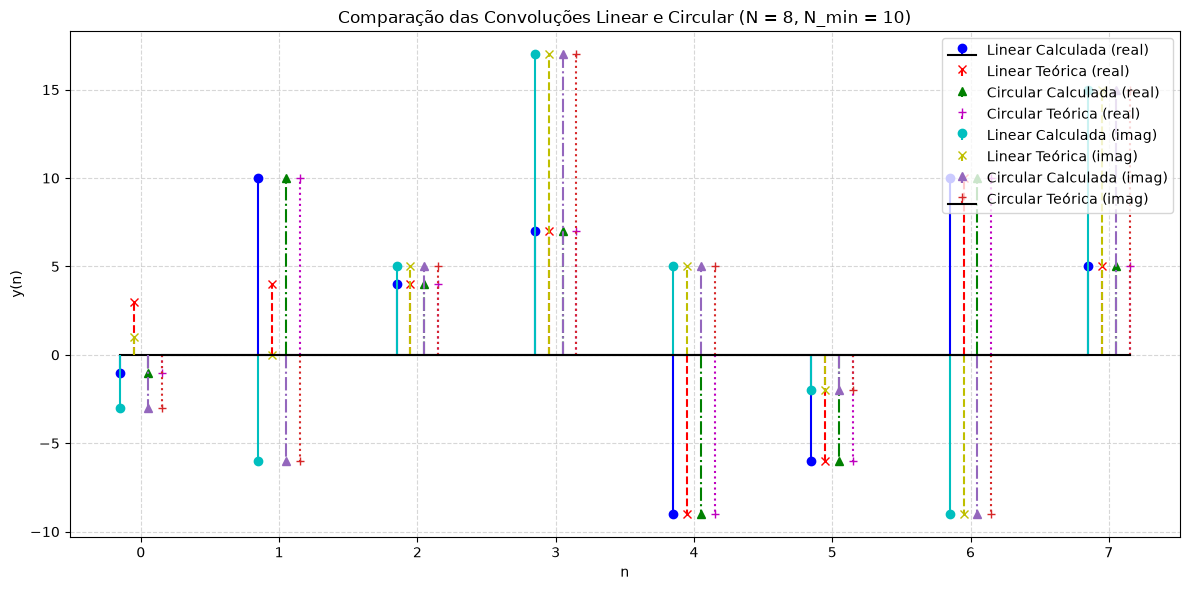

In [17]:
# ----------- SINAIS PARA TESTES -----------
'''
# Sinais aleatórios respeitando as condições de *zero-padding* e *aliasing temporal*
L1 = 3
L2 = 5
x1_n = np.random.rand(L1) + 1j * np.random.rand(L1)
x2_n = np.random.rand(L2) + 1j * np.random.rand(L2)

# Tamanho mínimo para não haver aliasing temporal (N_min = L1 + L2 - 1)
N_min = L1 + L2 - 1
N = N_min

'''
# Sinais pré-definidos para visualizar o alising temporal quando a condição N < N_min é verificada
x1_n = np.array([1 + 2j, 3 - 1j, 0 + 4j, 2 + 2j, -1 + 0j, 5 - 3j, 0 + 0j, -2 - 2j], dtype=complex)
x2_n = np.array([1 - 1j, 2 + 0j, 0 + 3j], dtype=complex)
N_min = len(x1_n) + len(x2_n) - 1
N = 8


# 1. Convolução Linear calculada via DFT/IDFT com padding correto (N >= N_min)
y_n_linear = convolucao_linear(x1_n, x2_n, N)

# 2. Convolução Circular com preenchimento prévio dos sinais até ao tamanho N
x1_n_pad = np.pad(x1_n, (0, N - len(x1_n)), 'constant')
x2_n_pad = np.pad(x2_n, (0, N - len(x2_n)), 'constant')
y_n_circular = convolucao_circular(x1_n_pad, x2_n_pad, N)

# 3. Convolução Linear Teórica (nativa do NumPy)
yn_linear_teo = np.pad(np.convolve(x1_n, x2_n), (0, max(0, N - N_min)))[:N]

# 4. Convolução Circular Teórica (nativa do NumPy)
yn_circular_teo = np.fft.ifft(np.fft.fft(x1_n, N) * np.fft.fft(x2_n, N))

# GRÁFICO COMPARATIVO DAS CONVOLUÇÕES LINEAR E CIRCULAR:

plt.figure(figsize=(12, 6))

n = np.arange(N)

# Partes REAIS:
plt.stem(n - 0.15, np.real(y_n_linear), linefmt='b-', markerfmt='bo', basefmt='k-', label='Linear Calculada (real)')
plt.stem(n - 0.05, np.real(yn_linear_teo), linefmt='r--', markerfmt='rx', basefmt='none', label='Linear Teórica (real)')
plt.stem(n + 0.05, np.real(y_n_circular), linefmt='g-.', markerfmt='g^', basefmt='none', label='Circular Calculada (real)')
plt.stem(n + 0.15, np.real(yn_circular_teo), linefmt='m:', markerfmt='m+', basefmt='none', label='Circular Teórica (real)')

# Partes IMAGINÁRIAS (Linha e marcador com a mesma cor nova, mas mantendo o marcador 'o', 'x', '^', '+'):
plt.stem(n - 0.15, np.imag(y_n_linear), linefmt='c-', markerfmt='co', basefmt='none', label='Linear Calculada (imag)')
plt.stem(n - 0.05, np.imag(yn_linear_teo), linefmt='y--', markerfmt='yx', basefmt='none', label='Linear Teórica (imag)')
plt.stem(n + 0.05, np.imag(y_n_circular), linefmt='C4-.', markerfmt='C4^', basefmt='none', label='Circular Calculada (imag)')
plt.stem(n + 0.15, np.imag(yn_circular_teo), linefmt='C3:', markerfmt='C3+', basefmt='k-', label='Circular Teórica (imag)')

plt.title(f'Comparação das Convoluções Linear e Circular (N = {N}, N_min = {N_min})')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()